<a href="https://colab.research.google.com/github/shubhishukla8176-arch/exfoliation-energy-ml/blob/main/notebooks/02_data_cleaning_and_validation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# Import the libraries required for data analysis

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

from google.colab import drive

drive.mount('/content/drive')

print("Google Drive connected!")


Mounted at /content/drive
Google Drive connected!


In [3]:

# Define the location of our project folder

project_folder = "/content/drive/MyDrive/MASC520_Project"

# Define the JSON file path

json_path = os.path.join(
    project_folder,
    "exfoliation_energy_dataset.json"
)

# Load the dataset

with open(json_path, "r") as file:
    records = json.load(file)

# Convert JSON records into a Pandas DataFrame

df = pd.DataFrame(records)

print("Dataset loaded successfully!")
print("Number of materials:", len(df))

# Display the first five records
df.head()


Dataset loaded successfully!
Number of materials: 813


,jid,atoms,exfoliation_energy
0,JVASP-10,"{'lattice_mat': [[1.6777483799, -2.9059452409,...",83.78
1,JVASP-60702,"{'lattice_mat': [[9.0670756842, 0.0, 0.0], [0....",88.81
2,JVASP-28397,"{'lattice_mat': [[0.0, -3.9587610833, 0.0], [-...",0.03
3,JVASP-3534,"{'lattice_mat': [[3.927408241, 0.0, 0.0], [0.0...",71.05
4,JVASP-323,"{'lattice_mat': [[3.4133421725, 0.0, 0.0], [-1...",89.57


In [4]:

# Display column names

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nFirst five material IDs:")
print(df["jid"].head())

print("\nFirst five exfoliation energy values:")
print(df["exfoliation_energy"].head())


Column names:
['jid', 'atoms', 'exfoliation_energy']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 813 entries, 0 to 812
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   jid                 813 non-null    object 
 1   atoms               813 non-null    object 
 2   exfoliation_energy  813 non-null    float64
dtypes: float64(1), object(2)
memory usage: 19.2+ KB

First five material IDs:
0       JVASP-10
1    JVASP-60702
2    JVASP-28397
3     JVASP-3534
4      JVASP-323
Name: jid, dtype: object

First five exfoliation energy values:
0    83.78
1    88.81
2     0.03
3    71.05
4    89.57
Name: exfoliation_energy, dtype: float64


In [5]:

# Count missing values in each column

missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

print("\nTotal missing values:")
print(missing_values.sum())


Missing values in each column:
jid                   0
atoms                 0
exfoliation_energy    0
dtype: int64

Total missing values:
0


In [6]:

# Count duplicate material IDs

duplicate_jids = df["jid"].duplicated().sum()

print("Number of duplicate material IDs:", duplicate_jids)

# Display duplicate records, if any

duplicates = df[df["jid"].duplicated(keep=False)]

if len(duplicates) > 0:
    print("\nDuplicate material records:")
    display(duplicates[["jid", "exfoliation_energy"]])
else:
    print("No duplicate material IDs found.")


Number of duplicate material IDs: 0
No duplicate material IDs found.


In [7]:

# Convert target values to numeric format for checking

target = pd.to_numeric(
    df["exfoliation_energy"],
    errors="coerce"
)

print("Target data type:", target.dtype)

print("\nTarget statistics:")
print(target.describe())

print("\nNumber of invalid target values:")
print(target.isna().sum())

print("\nNumber of infinite target values:")
print(np.isinf(target).sum())


Target data type: float64

Target statistics:
count    813.000000
mean     110.972399
std      111.698983
min        0.030000
25%       58.760000
50%       81.290000
75%      108.180000
max      948.930000
Name: exfoliation_energy, dtype: float64

Number of invalid target values:
0

Number of infinite target values:
0


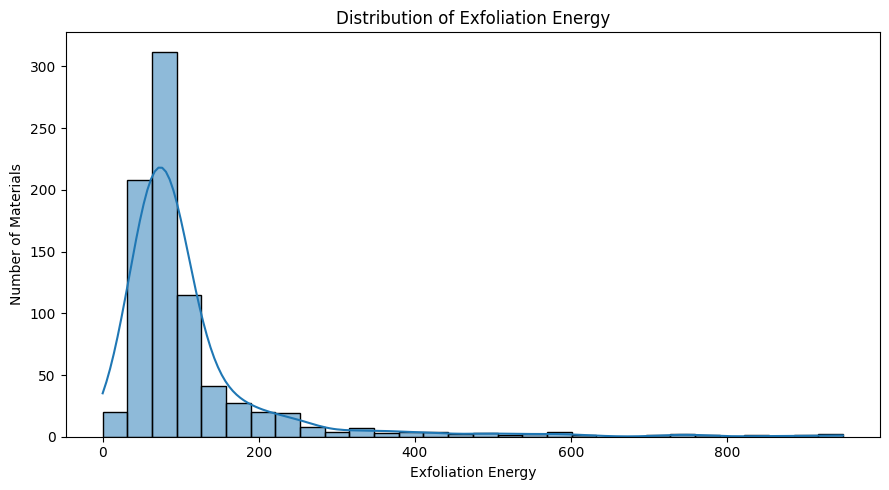

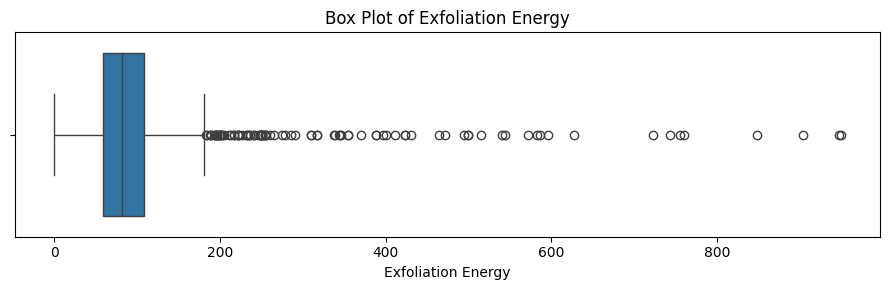

In [8]:

# Histogram of exfoliation energy

plt.figure(figsize=(9, 5))

sns.histplot(
    target,
    bins=30,
    kde=True
)

plt.xlabel("Exfoliation Energy")
plt.ylabel("Number of Materials")
plt.title("Distribution of Exfoliation Energy")

plt.tight_layout()
plt.show()


# Box plot of exfoliation energy

plt.figure(figsize=(9, 3))

sns.boxplot(x=target)

plt.xlabel("Exfoliation Energy")
plt.title("Box Plot of Exfoliation Energy")

plt.tight_layout()
plt.show()


In [9]:

# Inspect the first material

first_material = records[0]

print("Material ID:", first_material["jid"])

atoms_data = first_material["atoms"]

print("\nStructure information fields:")
print(atoms_data.keys())

print("\nLattice matrix:")
print(atoms_data.get("lattice_mat"))

print("\nAtomic elements:")
print(atoms_data.get("elements"))

print("\nAtomic coordinates:")
print(atoms_data.get("coords"))


Material ID: JVASP-10

Structure information fields:
dict_keys(['lattice_mat', 'coords', 'elements', 'abc', 'angles', 'cartesian', 'props'])

Lattice matrix:
[[1.6777483799, -2.9059452409, -0.0], [1.6777483799, 2.9059452409, -7e-16], [-0.0, -8e-16, 6.2208054657]]

Atomic elements:
['V', 'Se', 'Se']

Atomic coordinates:
[[0.0, 0.0, 0.0], [1.67775, -0.9686519373, 4.6529213966], [1.67775, 0.9686519373, 1.5678886034]]


In [10]:

structure_issues = []

for record in records:

    jid = record["jid"]
    atoms = record["atoms"]

    lattice = np.asarray(
        atoms.get("lattice_mat", []),
        dtype=float
    )

    coords = np.asarray(
        atoms.get("coords", []),
        dtype=float
    )

    elements = atoms.get("elements", [])

    problems = []

    # Check lattice matrix
    if lattice.shape != (3, 3):
        problems.append("Invalid lattice matrix shape")
    elif not np.all(np.isfinite(lattice)):
        problems.append("Non-finite lattice values")
    elif abs(np.linalg.det(lattice)) < 1e-10:
        problems.append("Zero or nearly zero cell volume")

    # Check atomic coordinates
    if coords.ndim != 2 or coords.shape[1:] != (3,):
        problems.append("Invalid coordinate shape")
    elif not np.all(np.isfinite(coords)):
        problems.append("Non-finite coordinates")

    # Check elements
    if len(elements) == 0:
        problems.append("No elements found")

    elif coords.ndim == 2 and len(coords) != len(elements):
        problems.append("Element-coordinate count mismatch")

    if problems:
        structure_issues.append({
            "jid": jid,
            "issues": "; ".join(problems)
        })

print("Total materials:", len(records))
print("Materials with basic structure issues:", len(structure_issues))

if structure_issues:
    display(pd.DataFrame(structure_issues).head(20))
else:
    print("All materials passed these basic structure checks.")


Total materials: 813
Materials with basic structure issues: 0
All materials passed these basic structure checks.


In [11]:

# Create a folder for validation outputs

results_folder = os.path.join(
    project_folder,
    "validation_results"
)

os.makedirs(results_folder, exist_ok=True)

# Save target statistics

target.describe().to_csv(
    os.path.join(results_folder, "target_statistics.csv")
)

# Save structure issues

pd.DataFrame(structure_issues).to_csv(
    os.path.join(results_folder, "structure_issues.csv"),
    index=False
)

# Save a basic validation summary

validation_summary = {
    "total_materials": len(df),
    "missing_jid": int(df["jid"].isna().sum()),
    "missing_atoms": int(df["atoms"].isna().sum()),
    "missing_exfoliation_energy": int(df["exfoliation_energy"].isna().sum()),
    "duplicate_jids": int(df["jid"].duplicated().sum()),
    "invalid_target_values": int(target.isna().sum()),
    "infinite_target_values": int(np.isinf(target).sum()),
    "materials_with_basic_structure_issues": len(structure_issues)
}

summary_df = pd.DataFrame(
    list(validation_summary.items()),
    columns=["Check", "Result"]
)

summary_df.to_csv(
    os.path.join(results_folder, "validation_summary.csv"),
    index=False
)

print("Validation results saved successfully!")
display(summary_df)


Validation results saved successfully!


,Check,Result
0,total_materials,813
1,missing_jid,0
2,missing_atoms,0
3,missing_exfoliation_energy,0
4,duplicate_jids,0
5,invalid_target_values,0
6,infinite_target_values,0
7,materials_with_basic_structure_issues,0
